# Ji et al. 2020 — Cutaneous SCC
## 02 · Cell-state manifold & trajectory (non-branching)

Fit a principal **curve** (scFates / ElPiGraph) to the scoped developmental compartment. The geometry is decided from the data, **shown not asserted** — and the evidence is non-branching:
- The embryonic modules **do not resolve into two competing arms**. A principal *tree* fit to the same manifold yields a Y whose two post-fork arms lean the **same** way on Gast−pSom (both pSom-positive), not opposite — so the formal fork is a shape artifact of the basal body, not a Gast-arm/pSom-arm bifurcation.
- Spatially, Gast and pSom **overlap** (smoothed Pearson ≈ +0.1) and **jointly oppose Crest** (≈ −0.88): the §1 non-branching signature — two co-varying programs with Crest as the inverse terminal gradient.
- Compared side-by-side to the branching Puram2017 archetype (Gast/pSom in *distinct* spokes) and the linear Sun/Kürten references (Gast/pSom overlapping), cSCC matches the **linear** references.

So a `curve` (not a `tree`) is the correct topology. Root at the **developmental origin** — the Gast/pSom-high, Crest-low tip (Crest is developmentally *late*, so it is the terminus, not the root).

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir] * 6))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
print('dataset:', name)

dataset: Ji2020_Skin-3


### Load the processed (scoped, annotated) manifold

(6897, 21042) | celltype: {'Basal': 2610, 'Mixed': 2034, 'Differentiated': 1411, 'TSK/EMT': 842}


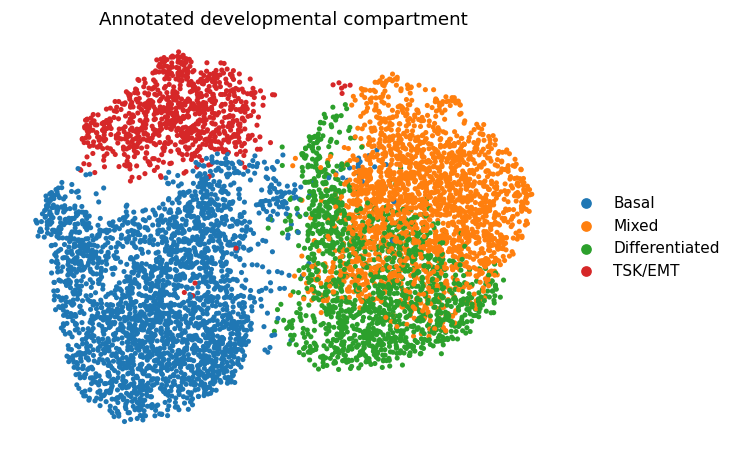

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
print(adata.shape, '| celltype:', adata.obs.celltype.value_counts().to_dict())
sc.pl.umap(adata, color='celltype', size=45, frameon=False, title='Annotated developmental compartment'); plt.show()

### Graph-smooth the embryonic signatures for geometry/rooting
Per the binding directive, geography and rooting are read off **smoothed** scores (raw per-cell scores are noise-dominated at 10x depth). Smooth via kNN-connectivity averaging.

In [4]:
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
for k in ['Gast', 'pSom', 'Crest']: adata.obs[k+'_sm'] = (A @ adata.obs[k].values) / deg
print('smoothed ranges:', {k: (round(adata.obs[k+'_sm'].min(),2), round(adata.obs[k+'_sm'].max(),2)) for k in ['Gast','pSom','Crest']})

smoothed ranges: {'Gast': (np.float64(-0.11), np.float64(0.09)), 'pSom': (np.float64(-0.04), np.float64(0.19)), 'Crest': (np.float64(-0.1), np.float64(0.1))}


### Test the geometry: does a tree resolve two *competing* arms?
Fit a PPT tree, root it at the Gast/pSom-high tip, and compare the Gast−pSom lean of the two **terminal (post-fork) segments**. The decision rule is explicit and the outcome is computed from the per-segment table, not assumed:
- **opposite signs** (one Gast-leaning, one pSom-leaning) → the modules segregate into two competing arms → **branching (tree)**;
- **same sign** → the modules co-vary rather than compete → the formal Y is a shape artifact → **non-branching (curve)**.
The printed verdict below is derived from the terminal-segment Gast−pSom values.

In [5]:
scf.tl.tree(adata, method='ppt', Nodes=50, ppt_lambda=5000, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(adata.uns['graph']['B']); dt_ = (Bt > 0).sum(0)
tips_t = np.where(dt_ == 1)[0]; forks_t = np.where(dt_ > 2)[0]
print('PPT tree: %d tips, %d fork(s)' % (len(tips_t), len(forks_t)))
# root the tree at the Gast/pSom-high tip, then compare the two terminal segments' Gast-pSom lean
Ft = adata.uns['graph']['F']
troot = int(max(tips_t, key=lambda t: (lambda o:o.Gast_sm.mean()+o.pSom_sm.mean()-o.Crest_sm.mean())(
    adata.obs.iloc[np.argsort(np.linalg.norm(adata.obsm['X_umap']-Ft[:,t],axis=1))[:100]])))
scf.tl.root(adata, troot); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
prof = adata.obs.groupby('seg', observed=True).agg(n=('seg','size'), t=('t','mean'),
        Gast=('Gast_sm','mean'), pSom=('pSom_sm','mean'), Crest=('Crest_sm','mean'))
prof['Gast_minus_pSom'] = prof.Gast - prof.pSom
print(prof.round(4).to_string())
# the two terminal (post-fork) segments = the two with no downstream child (leaves of pp_seg)
segdf = pd.DataFrame(adata.uns['graph']['pp_seg'])
internal = set(segdf['from']).intersection(set(segdf['to']))
term_nodes = [n for n in segdf['to'] if n not in internal]
term_segs = segdf[segdf['to'].isin(term_nodes)]['n'].astype(str).tolist()
gmp = prof.loc[[s for s in term_segs if s in prof.index], 'Gast_minus_pSom']
same_sign = bool((gmp < 0).all() or (gmp > 0).all())
verdict = ('SAME sign (%s) -> Gast and pSom do NOT segregate into opposing arms -> non-branching (curve)'
           % ('both Gast<pSom' if (gmp < 0).all() else 'both Gast>pSom')) if same_sign \
          else 'OPPOSITE signs -> a Gast arm and a pSom arm -> branching (tree)'
print('terminal segments', term_segs, '| Gast_minus_pSom =', gmp.round(4).to_dict())
print('->', verdict)

inferring a principal tree --> parameters used 
    50 principal points, sigma = 0.5, lambda = 5000, metric = euclidean
    fitting:  36%|###6      | 18/50 [00:01<00:02, 15.00it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
PPT tree: 3 tips, 1 fork(s)
node 17 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:04) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] l

### Global module relationships — overlap, not divergence
Smoothed Gast↔pSom co-vary (positive) while both oppose Crest — the non-branching signature.

In [6]:
from scipy.stats import pearsonr
gp = pearsonr(adata.obs.Gast_sm, adata.obs.pSom_sm)[0]
gc = pearsonr(adata.obs.Gast_sm, adata.obs.Crest_sm)[0]
pc = pearsonr(adata.obs.pSom_sm, adata.obs.Crest_sm)[0]
jc = pearsonr(adata.obs.Gast_sm + adata.obs.pSom_sm, adata.obs.Crest_sm)[0]
print('smoothed Gast-pSom  = %+.3f  (overlap: co-vary, not anti-podal spokes)' % gp)
print('smoothed Gast-Crest = %+.3f' % gc)
print('smoothed pSom-Crest = %+.3f' % pc)
print('smoothed (Gast+pSom)-Crest = %+.3f  (Crest = inverse terminal gradient)' % jc)

smoothed Gast-pSom  = +0.112  (overlap: co-vary, not anti-podal spokes)
smoothed Gast-Crest = -0.579
smoothed pSom-Crest = -0.730
smoothed (Gast+pSom)-Crest = -0.882  (Crest = inverse terminal gradient)


### Fit the principal curve (ElPiGraph) and certify it is fold-free
A `curve` is the correct non-branching topology. Fold-freeness is certified by the **node self-approach ratio** (min distance between graph-non-adjacent nodes / median edge length; >1 = fold-free), the Kürten §4 check, and the curve is rendered on the embedding below. Topology (2 tips, 0 forks) is stable across `Nodes`.

In [7]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
for N in [10, 15, 20]:
    scf.tl.curve(adata, Nodes=N, use_rep='X_umap', epg_lambda=0.5, epg_mu=50.0, seed=SEED, plot=False)
    sa, tp, fk = fold_diag(adata); print('curve Nodes=%d: %d tips, %d forks | fold ratio %.2f' % (N, tp, fk, sa))
scf.tl.curve(adata, Nodes=15, use_rep='X_umap', epg_lambda=0.5, epg_mu=50.0, seed=SEED, plot=False)
sa, tp, fk = fold_diag(adata)
B = np.asarray(adata.uns['graph']['B']); F = adata.uns['graph']['F']; tips = np.where((B>0).sum(0)==1)[0]
print('adopted curve Nodes=15: %d tips, %d forks | fold ratio %.2f (>1 = fold-free)' % (tp, fk, sa))
assert fk == 0 and sa > 1, 'topology/fold check failed'


inferring a principal curve --> parameters used 
    10 principal points, mu = 50.0, lambda = 0.5
    finished (0:00:01) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve Nodes=10: 2 tips, 0 forks | fold ratio 2.99
inferring a principal curve --> parameters used 
    15 principal points, mu = 50.0, lambda = 0.5
    finished (0:00:00) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve Nodes=15: 2 tips, 0 forks | fold ratio 2.97
inferring a principal curve --> parameters

### Select the root by biological rule
Root = the tip maximizing **(Gast + pSom) − Crest**: the Gast/pSom-high, Crest-low developmental origin. The opposite tip is Crest-high (terminal). Rule derived, shown, non-circular.

In [8]:
info = {}
for t in tips:
    dd = np.linalg.norm(adata.obsm['X_umap'] - F[:, t], axis=1)
    o = adata.obs.iloc[np.argsort(dd)[:100]]
    info[t] = (o.Gast_sm.mean(), o.pSom_sm.mean(), o.Crest_sm.mean(), o.celltype.value_counts().index[0])
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f  (%s)' % (t, *info[t]))
root = int(max(tips, key=lambda t: info[t][0] + info[t][1] - info[t][2]))
crest_tip = int(max(tips, key=lambda t: info[t][2]))
print('ROOT = tip %d (Gast/pSom-high, Crest-low origin) | Crest-high terminus = tip %d' % (root, crest_tip))

tip 0: Gast=-0.0315 pSom=+0.0190 Crest=+0.0382  (Basal)
tip 2: Gast=-0.0081 pSom=+0.0366 Crest=+0.0256  (Mixed)
ROOT = tip 2 (Gast/pSom-high, Crest-low origin) | Crest-high terminus = tip 0


### Root, compute pseudotime, verify the gradient
Along pseudotime the origin→terminus axis should run Gast/pSom-high → Crest-high (Gast and pSom co-decline, Crest rises) — the non-branching gradient.

In [9]:
scf.tl.root(adata, root)
scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, p = spearmanr(t, adata.obs[s]); print('  %-8s rho=%+.3f  p=%.1e' % (s, rho, p))
mil_ct = adata.obs.groupby('milestones', observed=True)['celltype'].agg(lambda s: s.value_counts().index[0])
mil_t = adata.obs.groupby('milestones', observed=True)['t'].mean()
newnames = {}; seen = {}
for m in mil_t.sort_values().index:
    nm = str(mil_ct[m])
    if nm in seen: newnames[m] = '%s_%d' % (nm, seen[nm]); seen[nm] += 1
    else: newnames[m] = nm; seen[nm] = 1
scf.tl.rename_milestones(adata, new=newnames)
print('milestones (origin -> terminus):', [newnames[m] for m in mil_t.sort_values().index])

node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:00) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm  rho=-0.499  p=0.0e+00
  pSom_sm  rho=-0.388  p=6.4e-247
  Crest_sm rho=+0.310  p=3.0e-153
milestones (origin -> terminus): ['Mixed', 'Basal']


### House linear orientation — pseudotime left -> right
The reference linear layout (`X_umap_lin`) orients the curve so pseudotime increases left→right. Applied as an axis swap/flip (no rotation), asserted against the pseudotime correlation.

In [10]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
cands = {'ident': xy, 'swap_yflip': np.column_stack([xy[:,1], -xy[:,0]]),
         'xflip': np.column_stack([-xy[:,0], xy[:,1]]), 'swap': np.column_stack([xy[:,1], xy[:,0]])}
best = max(cands, key=lambda k: np.corrcoef(cands[k][:,0], t)[0,1])
adata.obsm['X_umap_lin'] = cands[best]
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
print('orientation = %s | corr(x_lin, pseudotime) = %+.2f' % (best, r))
assert r > 0

orientation = xflip | corr(x_lin, pseudotime) = +0.98


### Save manifold

In [11]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (6897, 21042)


### `manifold.pdf` — pseudotime along the linear trajectory (house linear style)
Reference `(3.5,1.5)` linear panel, pseudotime `cividis`, left→right orientation, dataset citation.

saved manifold.pdf | root tip 2


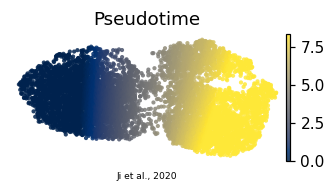

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.14,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.pdf | root tip', root)